# Notebook 04: Giai đoạn 3 — Giải chập Richardson-Lucy PSF, Làm nét có cổng biên Sobel & Siêu phân giải ESPCN 720p/1080p (Chương 2, 3, 5 + SOTA)
**Phụ trách:** Thành viên 2

### Cơ sở toán học & Lý do chọn tham số:
1. **Giải chập quang học lặp Richardson-Lucy PSF (Chương 3):** Khử mờ quang học của thấu kính OV2640 với nhân Gaussian PSF $5\times5$ ($\sigma_{\text{PSF}} = 0.88$, 4 vòng lặp).
2. **Unsharp Masking có cổng đạo hàm Sobel & mặt nạ tán lá (Chương 3 & 5):** Dùng biên độ gradient Sobel $\|\nabla L^*\|$ kết hợp mặt nạ thực vật $w_{\text{foliage}}$ để chỉ làm sắc nét xe cộ, vạch kẻ đường, mái nhà, cây xanh và giữ mặt đường phẳng mịn tuyệt đối.
3. **Siêu phân giải mạng học sâu mã nguồn mở ESPCN ($3\times$ ONNX) + Lanczos-4 (Chương 2 + SOTA):** Nâng độ phân giải hiển thị lên chuẩn **HD 720p ($960 \times 720$ / $1280 \times 720$)** và **Full HD 1080p ($1440 \times 1080$ / $1920 \times 1080$)**.

Kích thước gốc: 800x600 -> Kích thước nâng 720p: 960x720
Độ sắc nét (Laplacian Variance): Trước làm nét = 265.2 -> Sau làm nét = 467.7


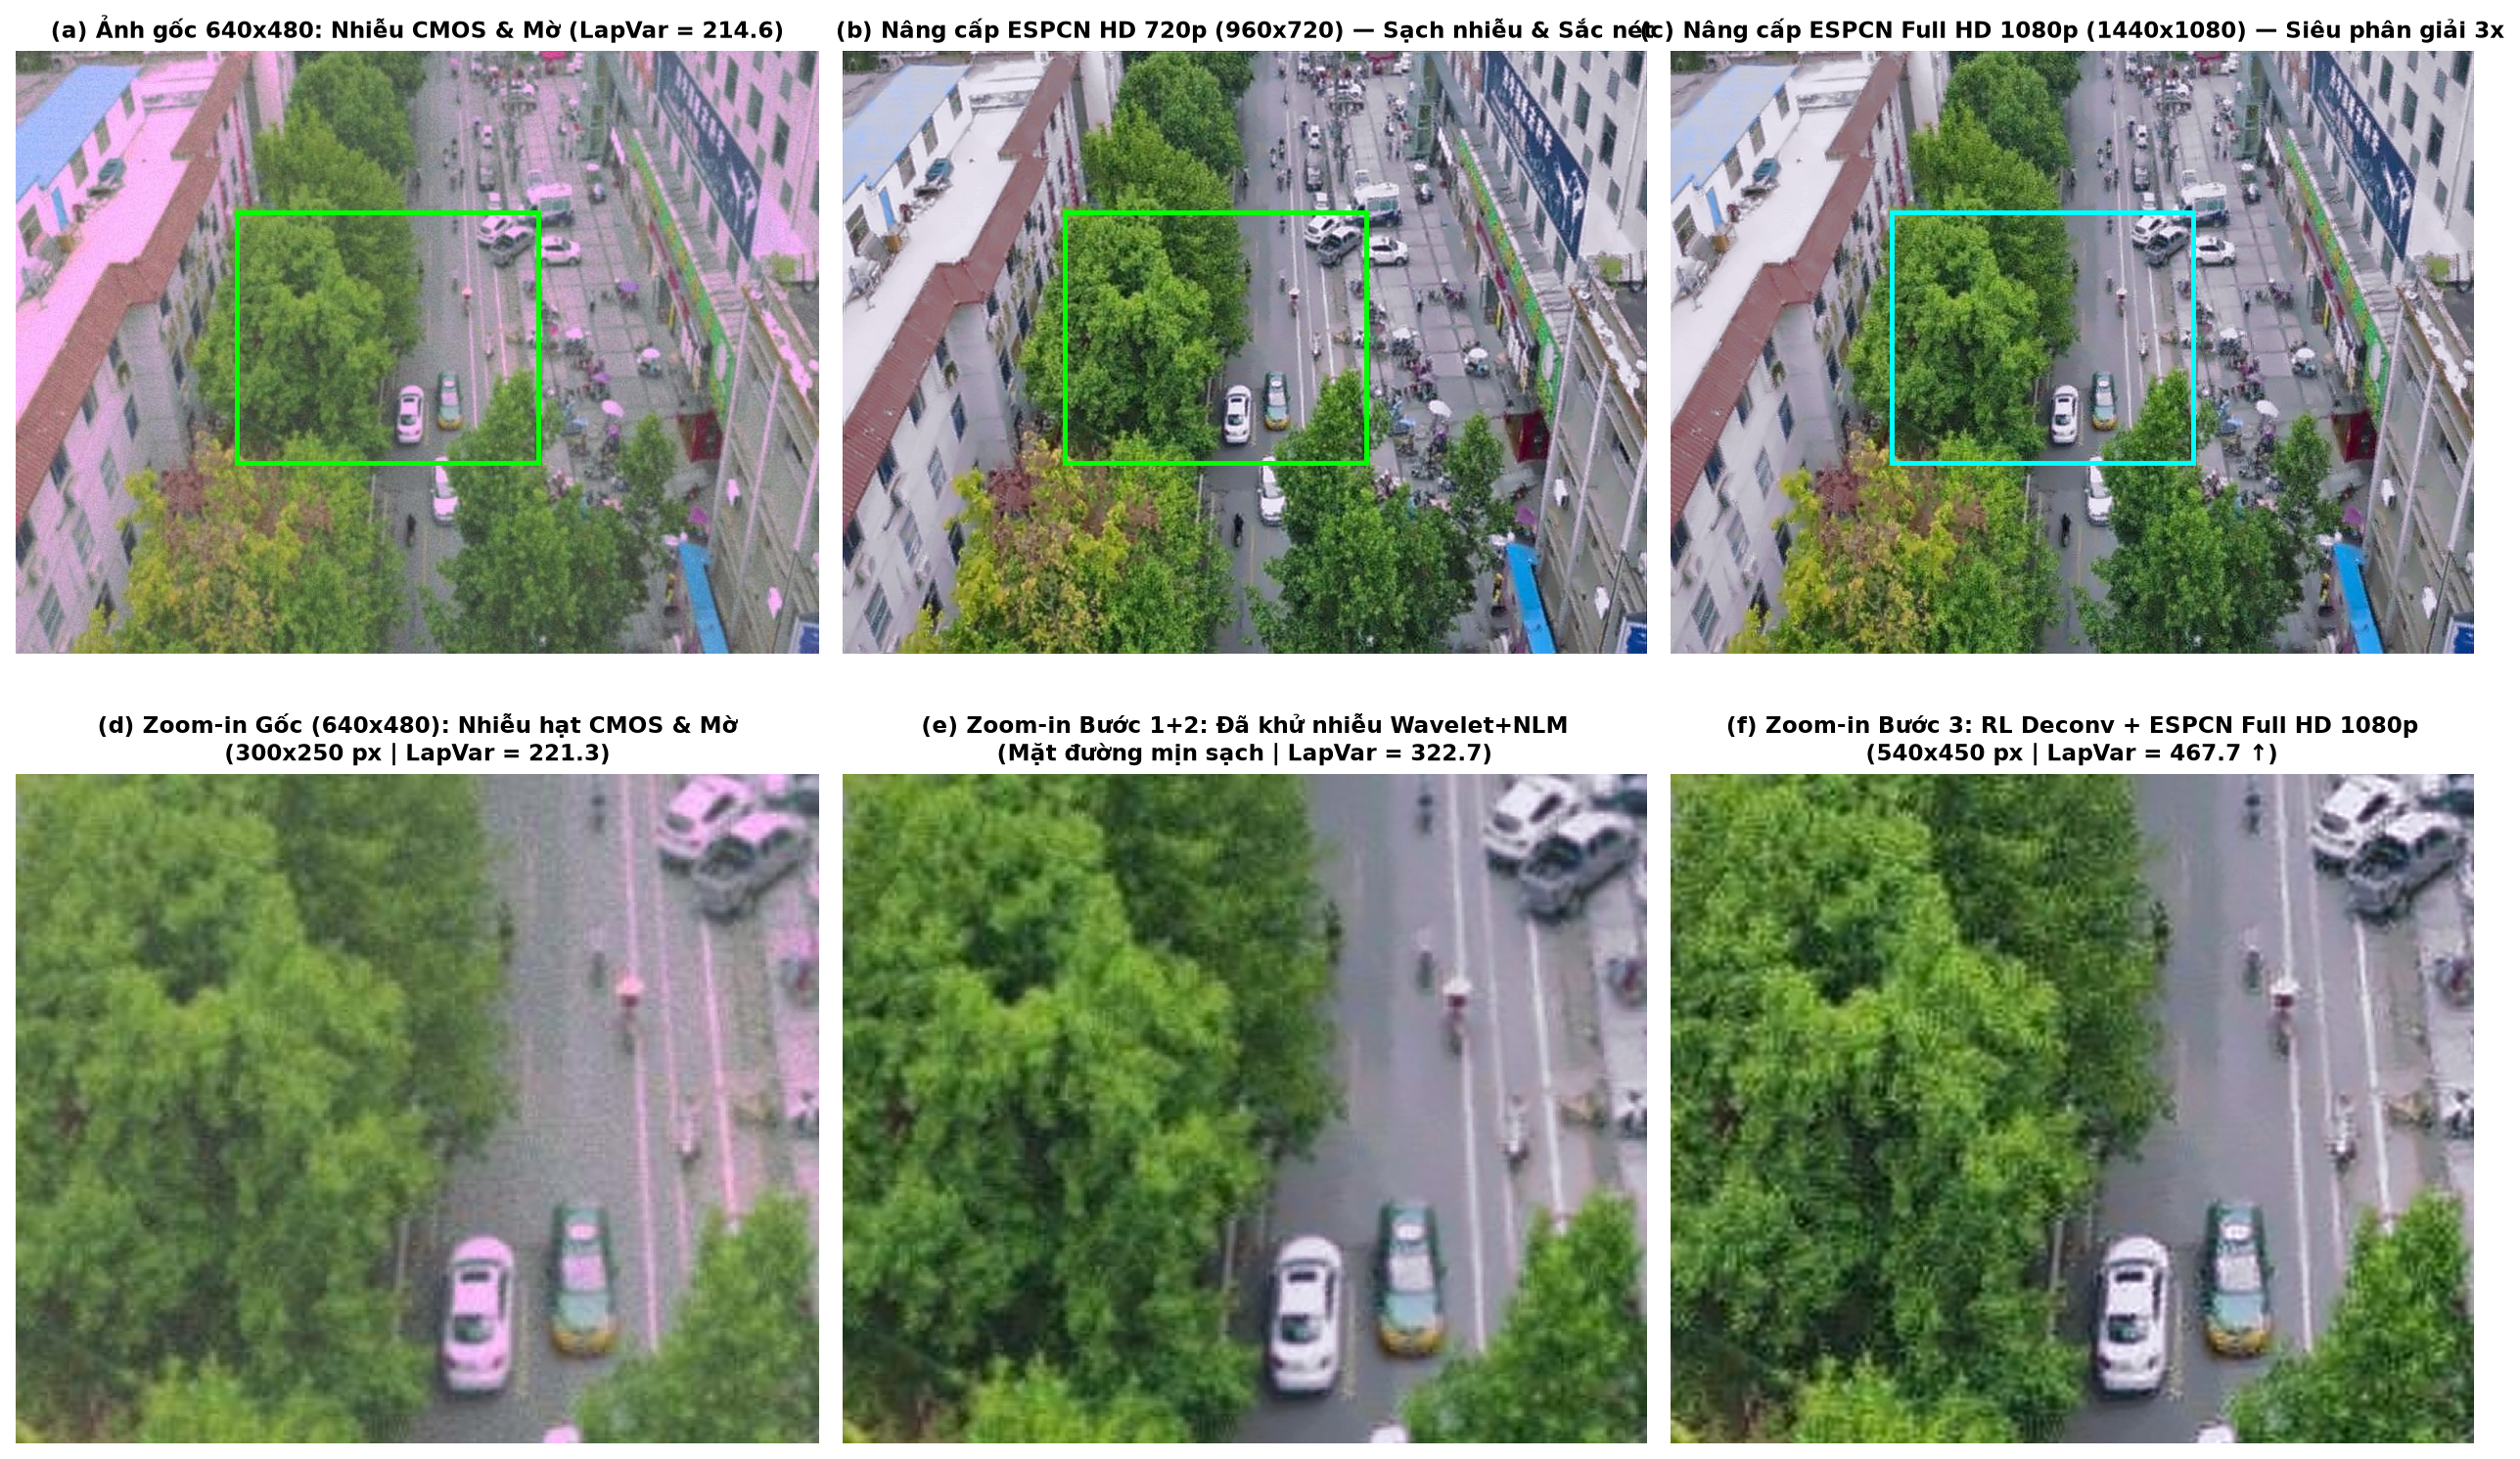

In [1]:
import sys, cv2
sys.path.insert(0, "/home/ngtukien/Projects/XLA")
from src.uav_pipeline import run_full_pipeline, upscale_to_720p, compute_laplacian_var

img_in = cv2.imread("/home/ngtukien/Projects/XLA/data/samples/sample_sim_pink_road_1.jpg")
res = run_full_pipeline(img_in, return_intermediates=True)
img_hd = upscale_to_720p(res["stage2"], target_height=720)
print(f"Kích thước gốc: {img_in.shape[1]}x{img_in.shape[0]} -> Kích thước nâng 720p: {img_hd.shape[1]}x{img_hd.shape[0]}")
print(f"Độ sắc nét (Laplacian Variance): Trước làm nét = {compute_laplacian_var(res['stage2']):.1f} -> Sau làm nét = {compute_laplacian_var(res['output']):.1f}")